# M03-2 | 讀懂 XNNPACKQuantizer 貼的標籤

M03-1 的標籤是手貼的：我們決定位置、我們決定規格。寫自己的 Quantizer 之前，先讀懂一個真實的 Quantizer 貼了什麼。
這裡用 torchao 測試版的 XNNPACKQuantizer（`torchao.testing.pt2e._xnnpack_quantizer`，torchao 為自己的單元測試留的一份 XNNPACK 後端 Quantizer），
per-channel weight 的設定。

讀每一張標籤時，只要回答三個問題：

- **位置**：哪一條輸入邊（`input_qspec_map`），或哪個 node 的輸出（`output_qspec`）。
- **規格**：哪一份 `QuantizationSpec`（dtype、整數範圍、方案、observer）。
- **有沒有**：沒有標籤、或規格是 `None` 的位置，就不量化。

這本 notebook 讀三個模型：

- **A.** conv → relu：conv 和 relu 之間為什麼沒有量化點。
- **B.** residual：add 的兩條輸入邊，以及 conv 什麼時候自己有輸出標籤。
- **C.** cat_pool：哪些 op 沒被標到。

In [1]:
import copy

import torch

from common.graph_utils import qspec_summary, unannotated_ops
from common.models import example_inputs, get_model
from common.pt2e import ANNOTATION_KEY, Quantizer, export_module, get_xnnpack_quantizer, prepare_pt2e, quiet
from common.viz import annotation_notes, draw

quiet()
_ = torch.manual_seed(0)

## 拿到 Quantizer 真正標過的圖

最直接的做法是對 export 出來的圖呼叫 `quantizer.annotate(gm)`，但這樣看到的圖和 Quantizer 實際標的不一樣：
M03-1 列過 `prepare_pt2e` 的步驟，BN 在 `annotate` **之前**就被折進 conv 了。而 `annotate` 一結束，`prepare_pt2e` 就接著插 observer，標籤不好讀。

所以包一層：`CaptureLabels` 把每個方法轉給裡面的 Quantizer，只在 `annotate` 結束的當下複製一份圖。

In [2]:
class CaptureLabels(Quantizer):
    def __init__(self, inner: Quantizer):
        self.inner = inner
        self.annotated: torch.fx.GraphModule | None = None

    def transform_for_annotation(self, model):
        return self.inner.transform_for_annotation(model)

    def annotate(self, model):
        self.inner.annotate(model)
        self.annotated = copy.deepcopy(model)  # 標完、還沒插 observer 的圖
        return model

    def validate(self, model):
        self.inner.validate(model)


def read_labels(model_name):
    """對指定模型跑一次 prepare_pt2e，回傳 XNNPACKQuantizer 標完的圖。"""
    gm = export_module(get_model(model_name).eval(), example_inputs(4))
    xnnpack, _ = get_xnnpack_quantizer(is_per_channel=True)
    capture = CaptureLabels(xnnpack)
    prepare_pt2e(gm, capture)
    assert capture.annotated is not None
    return capture.annotated

下面三段都把 Quantizer 貼的標籤直接寫在圖上每個 node 底下：每條輸入邊一行「邊 上游：規格」，輸出一行「輸出：規格」。
規格縮寫成 dtype + 粒度 + 方案，例如 `int8 per-tensor affine`；`不量化` 表示這條邊的規格是 `None`。

程式裡的 `annotation_notes(圖)` 是本專案畫圖用的小工具（`common/viz.py`），不是 torchao 的 API：
它讀每個 node 的 `node.meta["quantization_annotation"]`，轉成上面這些文字，交給 `draw` 的 `notes` 參數畫在 node 底下。
讀標籤只要看圖上的文字。

## A. conv → relu：conv 和 relu 之間沒有量化點

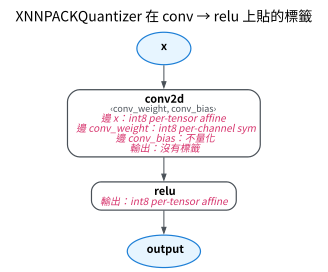

In [3]:
labeled = read_labels("conv_relu")
draw(labeled, notes=annotation_notes(labeled), title="XNNPACKQuantizer 在 conv → relu 上貼的標籤")

請看 conv2d 底下的四行：

- 三條輸入邊：activation `x`、weight、bias。activation 是 per-tensor affine，weight 是 per-channel symmetric，bias 的規格是 `None`（這份設定不量化 bias，保持 fp32）。
- **conv2d 的輸出沒有標籤，輸出標籤貼在 relu 上**。所以 conv 和 relu 之間不會插 observer，後端可以把 conv + relu 當成一個 kernel。這就是 PT2E 裡的 fusion：它不是改圖，只是「不在中間貼標籤」。

兩份規格的完整內容（`common.graph_utils.qspec_summary`）：

In [4]:
conv = next(n for n in labeled.graph.nodes if n.name == "conv2d")
ann = conv.meta[ANNOTATION_KEY]
# 複製出來的圖，標籤裡的 key 仍是原圖的 node 物件，所以改用名字查
specs = {producer.name: spec for producer, spec in ann.input_qspec_map.items()}
x, weight, bias = (a.name for a in conv.args[:3])
print("activation：", qspec_summary(specs[x]).replace("\n", "，"))
print("weight：    ", qspec_summary(specs[weight]).replace("\n", "，"))

activation： int8 per-tensor affine [-128,127]，HistogramObserver
weight：     int8 per-channel symmetric [-127,127]，PerChannelMinMaxObserver, ch_axis=0


In [5]:
relu = next(n for n in labeled.graph.nodes if n.name == "relu")
assert ann.output_qspec is None and specs[bias] is None
assert relu.meta[ANNOTATION_KEY].output_qspec is not None

activation 用 `HistogramObserver`、weight 用 `PerChannelMinMaxObserver` 並沿 output channel（`ch_axis=0`）各算一個 scale，這是這份 XNNPACKQuantizer 預設設定的選擇（M02-1 比較過各種 observer）。

## B. residual：add 的兩條輸入邊

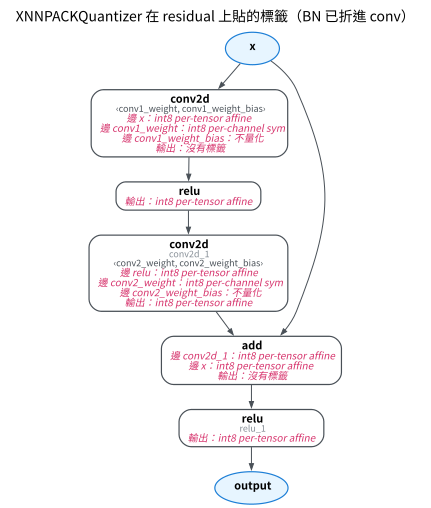

In [6]:
labeled = read_labels("residual")
draw(labeled, notes=annotation_notes(labeled), title="XNNPACKQuantizer 在 residual 上貼的標籤（BN 已折進 conv）")

- 圖上已經沒有 `batch_norm`：Quantizer 看到的是 BN 折完的圖。conv 的 weight 換成折過的值，bias 是折 BN 時算出的新常數（`conv1_weight_bias`）。
- `add` 的兩條輸入邊（`conv2d_1 → add`、`x → add`）都有標籤，輸出標籤貼在後面的 `relu_1`：add + relu 也被當成一個 pattern。
- 第一個 conv 後面接 relu，所以沒有輸出標籤；**第二個 conv（`conv2d_1`）後面接的是 add，沒有 relu 可以融，它自己就有輸出標籤**。

同一個 Quantizer、同一種 op，標籤卻不一樣：Quantizer 是看 op 的前後文決定的，不是一種 op 對應一種標籤。

In [7]:
anns = {n.name: n.meta.get(ANNOTATION_KEY) for n in labeled.graph.nodes}
assert "batch_norm" not in anns
assert anns["conv2d"].output_qspec is None and anns["conv2d_1"].output_qspec is not None
assert len(anns["add"].input_qspec_map) == 2 and anns["add"].output_qspec is None
assert anns["relu_1"].output_qspec is not None

## C. cat_pool：哪些 op 沒被標到

沒被標到的 op 不會報錯，只是留在 fp32。用 `unannotated_ops`（`common.graph_utils`）列出沒有標籤的 op，在圖上也標成「沒有標籤」（`annotation_notes` 加上 `unlabeled=True`）：

沒有標籤的 op： ['cat', 'max_pool2d']


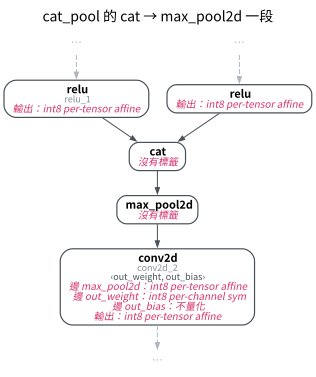

In [8]:
labeled = read_labels("cat_pool")
left = [n.name for n in unannotated_ops(labeled)]
print("沒有標籤的 op：", left)
draw(labeled, focus=["cat", "max_pool2d"], hops=1, notes=annotation_notes(labeled, unlabeled=True),
     title="cat_pool 的 cat → max_pool2d 一段")

In [9]:
assert {"cat", "max_pool2d"} <= set(left)

`cat` 與 `max_pool2d` 是 XNNPACK 能量化的 op，卻沒有標籤。原因在 M01-2 查過：

- 這份 torchao 測試版的 `cat` annotator 靠 `node.meta["source_fn_stack"]` 找 pattern，torch 2.14 的 export 不再填這個欄位，於是**靜默失效**。
- `max_pool2d` 的 annotator 本身沒壞：它的規則是「和輸入共用 qparams」，輸入 `cat` 沒有標籤，它也就跟著沒標。

executorch 版的 XNNPACKQuantizer 沒有這個問題（M08-1 對照）。

教訓：用任何 Quantizer 之前，先把標籤畫出來，確認以為會被量化的 op 真的有標籤。
自己寫 Quantizer 時，用 `node.target` 找 op 比依賴 `source_fn_stack` 這類 metadata 穩定，這是 M03-3 的做法。

## 小結

- 每張標籤只回答三件事：位置（邊或輸出）、規格（`QuantizationSpec`）、有沒有。
- fusion 在標籤上的樣子：pattern 中間的 node 不貼輸出標籤，輸出標籤貼在 pattern 的最後一個 op（conv + relu 貼在 relu、add + relu 貼在 relu）。
- Quantizer 看的是 BN 折完的圖，並依 op 的前後文決定標籤；沒被標到的 op 不會報錯，要自己檢查。